# T03 — Interconnected grounding systems and the three impedances

In a low-voltage distribution network (German *Ortsnetz*) the earth
electrode of the substation is not alone: the PEN conductors of the
cables connect it to the foundation earth electrodes (*Fundamenterder*)
of every house. A current fed into the substation earth then leaves
the soil at many places. This tutorial builds a small network of that
kind, explains the three impedances `groundfield` reports, and
reproduces the result with a second, independent method: the mutual
grounding-impedance matrix $Z_G$ of the earth electrodes combined with
the admittances of the cables.

**You will learn**

- how electrodes become one *cluster* through ideal bonds and how
  finite-impedance conductors (PEN cables) join clusters into a
  network;
- the difference between the **input impedance**, the **cluster
  impedance** and the **electrode impedance**, and the split factor
  that links them;
- how to compute $Z_G$ and reduce a network with the nodal equation
  $(Y_L + Z_G^{-1})\,u = i$.

Runtime: a few seconds.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import groundfield as gf

print("groundfield", gf.__version__)

groundfield 0.15.0


## The network

- **Substation earth:** a square ring of 4 m × 4 m at 0.6 m depth and
  three driven rods of 4 m at its corners. The rods are bonded to the
  ring with *ideal* conductors (`create_conductor` without a cross
  section): the four electrodes become one galvanic **cluster** with
  one common potential.
- **Houses:** a foundation earth electrode of 10 m × 10 m at 0.8 m
  depth per house, 30 m apart along a street.
- **PEN cable:** a radial chain station → house 1 → house 2 → …,
  aluminium with 150 mm² cross section, insulated from the soil
  (`coupling_to_soil="isolated"`). A conductor with a cross section is
  a *branch* with a series resistance $R = \rho_\mathrm{Al}\,l/A$; the
  clusters it connects keep their own potentials.
- **Soil:** homogeneous, 100 Ω·m. **Source:** 1 A into the substation,
  returning through remote earth.

In [2]:
RHO_AL = 2.82e-8  # resistivity of aluminium in Ohm m
A_PEN = 150e-6  # PEN cross section in m^2


def lv_network(n_houses=3, rho=100.0, *, pen=True):
    # Substation earth (one cluster) plus n_houses foundations on a PEN chain.
    world = gf.create_world(soil=gf.HomogeneousSoil(rho=rho))
    gf.create_electrode(
        world,
        "grid_mesh",
        name="station",
        corner=(-2.0, -2.0, 0.6),
        size=(4.0, 4.0),
        n_x=1,
        n_y=1,
    )
    for k, (x, y) in enumerate([(-2.0, -2.0), (2.0, -2.0), (2.0, 2.0)]):
        gf.create_electrode(
            world, "rod", name=f"station_rod_{k}", position=(x, y, 0.6), length=4.0
        )
        gf.create_conductor(
            world, name=f"bond_{k}", start="station", end=f"station_rod_{k}"
        )  # ideal
    previous = "station"
    for k in range(n_houses):
        x0 = 30.0 * (k + 1)
        gf.create_electrode(
            world,
            "grid_mesh",
            name=f"house_{k}",
            corner=(x0 - 5.0, 10.0, 0.8),
            size=(10.0, 10.0),
            n_x=1,
            n_y=1,
        )
        if pen:
            gf.create_conductor(
                world,
                name=f"pen_{k}",
                start=previous,
                end=f"house_{k}",
                conductor_type="pen",
                resistivity=RHO_AL,
                cross_section=A_PEN,
                coupling_to_soil="isolated",
            )
        previous = f"house_{k}"
    gf.create_source(world, attached_to="station", magnitude=1.0)
    return world


world = lv_network()
engine = gf.create_engine(segment_length=1.0, frequencies=[50.0])
result = engine.solve(world)
print(result.summary())
print("clusters:", sorted({tuple(m) for m in result.clusters.values()}))

FieldResult(backend='image', n_freq=1, n_electrodes=7, n_segments=148)
clusters: [('house_0',), ('house_1',), ('house_2',), ('station', 'station_rod_0', 'station_rod_1', 'station_rod_2')]


## Three impedances

| Quantity | Definition | Accessor |
|---|---|---|
| input impedance $Z_\mathrm{in}$ | $(\varphi_\mathrm{fed} - \varphi_\mathrm{return}) / I_\mathrm{source}$ | `result.input_impedance()` |
| cluster impedance $Z_c$ | $\varphi_c / \sum_{e \in c} I_e$ (leakage of the cluster only) | `result.cluster_impedance(name)` |
| electrode impedance $Z_e$ | $\varphi_e / I_e$ of one electrode | `result.grounding_impedance(name)` |

The **input impedance** is what an earth tester connected to the
substation measures against remote earth, and what a fault at the
substation sees: the whole network. The **cluster impedance** is the
local electrode alone, but in the field of its neighbours. The
**electrode impedance** of a member of a cluster only tells how the
cluster current divides among its members.

The fraction of the source current that the fed cluster itself leaks
into the soil is the **split factor** $s = I_c / I_\mathrm{source}$,
and $Z_\mathrm{in} = s \cdot Z_c$.

In [3]:
z_in = result.input_impedance()[0]
z_cluster = result.cluster_impedance("station")[0]
s = gf.split_factor(result, world)
z_alone = engine.solve(lv_network(n_houses=0)).input_impedance()[0]

print(f"input impedance of the network   Z_in  = {z_in.real:.4f} Ohm")
print(f"cluster impedance of the station Z_c   = {z_cluster.real:.4f} Ohm")
print(f"split factor                     s     = {s.real:.4f}")
print(f"s * Z_c                                = {(s * z_cluster).real:.4f} Ohm")
print(f"substation earth without houses        = {z_alone.real:.4f} Ohm")

input impedance of the network   Z_in  = 1.7253 Ohm
cluster impedance of the station Z_c   = 9.0971 Ohm
split factor                     s     = 0.1896
s * Z_c                                = 1.7253 Ohm
substation earth without houses        = 7.8002 Ohm


In [4]:
assert abs(z_in - s * z_cluster) < 1e-12 * abs(z_in)
assert z_in.real < 0.5 * z_alone.real  # the houses carry most of the current
assert (
    z_cluster.real > z_alone.real
)  # the neighbours raise the station's local potential
currents = [i[0] for i in result.electrode_currents.values()]
assert (
    abs(sum(currents) - 1.0) < 1e-12
)  # Kirchhoff: all of the 1 A leaves through the soil

Three observations:

1. The network impedance is far below the impedance of the substation
   earth alone: most of the current leaves the soil at the houses.
2. The station's *cluster* impedance is *higher* than the impedance of
   the station alone: the houses lift the soil potential around the
   station, so the station's own leakage current meets a higher
   potential. Using the cluster impedance as "the grounding impedance
   of the station" therefore overestimates the network value by a
   factor $1/s$.
3. The sum of all leakage currents is the source current
   (Kirchhoff's current law); the table below shows where it goes.

In [5]:
table = result.to_dataframe()
table["current_a"] = table["current_a"].apply(lambda c: c.real)
table[["electrode", "cluster", "current_a"]]

,electrode,cluster,current_a
0,station,station,0.090968
1,station_rod_0,station,0.033860
2,station_rod_1,station,0.032114
3,station_rod_2,station,0.032706
4,house_0,house_0,0.269229
5,house_1,house_1,0.261219
6,house_2,house_2,0.279904


## How the impedances depend on the size of the network

`gf.sweep` builds one world per parameter combination, solves it and
returns a table. The keyword `quantity` selects the impedance of the
default response: `"input"` (the default) or `"cluster"`.

,n_houses,abs_Z,abs_Z_cluster
0,0,7.800204,7.800204
1,1,3.370421,8.536324
2,2,2.258386,8.878618
3,3,1.725250,9.097104
4,5,1.196066,9.378113
5,8,0.839763,9.630268


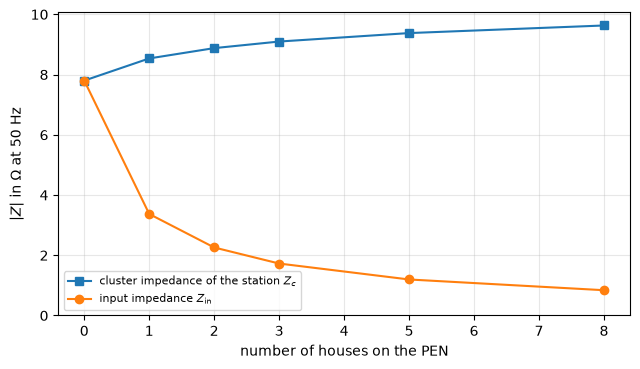

In [6]:
n_values = [0, 1, 2, 3, 5, 8]
sweep_in = gf.sweep(lv_network, engine, axes={"n_houses": n_values})
sweep_cl = gf.sweep(lv_network, engine, axes={"n_houses": n_values}, quantity="cluster")

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(
    n_values, sweep_cl["abs_Z"], "s-", label=r"cluster impedance of the station $Z_c$"
)
ax.plot(n_values, sweep_in["abs_Z"], "o-", label=r"input impedance $Z_\mathrm{in}$")
ax.set_xlabel("number of houses on the PEN")
ax.set_ylabel(r"$|Z|$ in $\Omega$ at 50 Hz")
ax.set_ylim(0, None)
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
fig.tight_layout()
sweep_in[["n_houses", "abs_Z"]].assign(abs_Z_cluster=sweep_cl["abs_Z"].to_numpy())

In [7]:
assert np.all(np.diff(sweep_in["abs_Z"]) < 0)  # every house lowers Z_in
assert (
    abs(sweep_in["abs_Z"].iloc[0] / sweep_cl["abs_Z"].iloc[0] - 1.0) < 1e-12
)  # no houses: identical
assert np.all(np.diff(sweep_cl["abs_Z"]) > 0)  # the cluster impedance rises

## Second method: the mutual grounding-impedance matrix

The soil couples every earth electrode with every other one. For $n$
clusters this is described by the symmetric matrix $Z_G$: column $j$
holds the cluster potentials when 1 A is fed into cluster $j$ and all
other clusters float. The cables form a separate, purely metallic
network with the nodal admittance matrix $Y_L$. With the vector $i$ of
currents fed into the nodes, the node potentials $u$ satisfy

$$
\bigl(Y_L + Z_G^{-1}\bigr)\, u = i .
$$

This is the *characteristic matrix* of a network: once $Z_G$ is known,
any cable configuration can be evaluated without a new field solution.
`gf.solve_mutual_matrix` computes $Z_G$ for a world that contains only
the earth electrodes; `offdiag="galerkin"` gives the reciprocal
matrix whose nodal reduction reproduces the coupled solution exactly.

In [8]:
anchors = ["station", "house_0", "house_1", "house_2"]
z_g = gf.solve_mutual_matrix(lv_network(pen=False), engine, anchors, offdiag="galerkin")

# Nodal admittance matrix of the PEN chain station -> house_0 -> house_1 -> house_2.
y_l = np.zeros((4, 4), dtype=complex)
for k, conductor in enumerate(c for c in world.conductors if c.name.startswith("pen_")):
    y = 1.0 / conductor.series_resistance
    y_l[[k, k + 1], [k, k + 1]] += y
    y_l[[k, k + 1], [k + 1, k]] -= y

i_fed = np.array([1.0, 0.0, 0.0, 0.0], dtype=complex)
u = np.linalg.solve(y_l + np.linalg.inv(z_g), i_fed)

np.set_printoptions(precision=4, suppress=True)
print("Z_G in Ohm:")
print(z_g.real)
print(f"nodal reduction: Z_in = {u[0].real:.10f} Ohm")
print(f"field solution:  Z_in = {z_in.real:.10f} Ohm")
print(f"leakage currents from Z_G^-1 u: {np.round((np.linalg.inv(z_g) @ u).real, 4)} A")

Z_G in Ohm:
[[7.8002 0.4803 0.2589 0.1751]
 [0.4803 5.2498 0.5401 0.2664]
 [0.2589 0.5401 5.2499 0.5402]
 [0.1751 0.2664 0.5402 5.2499]]
nodal reduction: Z_in = 1.7252500437 Ohm
field solution:  Z_in = 1.7252500437 Ohm
leakage currents from Z_G^-1 u: [0.1896 0.2692 0.2612 0.2799] A


In [9]:
assert np.allclose(z_g, z_g.T, rtol=1e-12)  # reciprocity
assert abs(u[0] / z_in - 1.0) < 1e-9
leak = np.linalg.inv(z_g) @ u
assert abs(leak[0] - s) < 1e-9  # the station's share is the split factor

The two methods agree to round-off. The diagonal of $Z_G$ holds the
cluster impedances of the stand-alone electrodes; the off-diagonal
entries are the *transfer impedances* — the potential one electrode
acquires when another one leaks 1 A. They fall off roughly with the
inverse distance.

## Ideal bonds, branches and leaking conductors

`create_conductor` covers three cases:

| Call | Model |
|---|---|
| no `cross_section` (default) | ideal bond: both ends become one cluster |
| `cross_section=...`, `coupling_to_soil="isolated"` | insulated cable: series branch $R + j\omega L$, no leakage |
| `cross_section=...`, `coupling_to_soil="galvanic"` with `discretize_segment_length` | bare conductor in the soil: a branch that also leaks along its length |

The inductance of a branch ($j\omega L$, `inductance_model="neumann"`)
makes the network frequency dependent; tutorial
[T04](T04_frequency_response_and_rho_f.ipynb) builds on that.

## Summary

- Report the **input impedance** for a network; the cluster impedance
  describes the local electrode only, and $Z_\mathrm{in} = s\,Z_c$.
- Kirchhoff's current law over `electrode_currents` is a free
  plausibility check of every solve.
- The matrix $Z_G$ plus the cable admittances reproduces the field
  solution and lets you study cable variants without a new solve.

**Next:** [T04 — frequency response and the rho-f
model](T04_frequency_response_and_rho_f.ipynb).